# Assignment 2: training pipeline

You're using a notebook for this stage. If you'd rather use a script,
write `train.py` instead and delete this file. `main.py` refuses to run if
it finds both `train.py` and `train.ipynb`, so exactly one of them must exist.

Replace this cell and everything below it with your own code. When run
via `uv run python main.py train`, this notebook must, start to finish, with no
manual steps in between:

- Get your Roboflow API key via `from api_key import load_api_key`, so that it
  works whether the key is in your `.env` file or in the environment, and
  download your dataset version from Roboflow Universe.
- Finetune yolo11n/yolo11s (or the -cls variant) on that dataset, from the
  pretrained checkpoint.
- Evaluate on the test split against the two baselines named in the brief: the
  pretrained COCO model zero-shot, and a trivial predict-nothing / majority
  class baseline.
- Sweep the confidence threshold, compute the expected cost at each point from
  the cost matrix you defined in REPORT.md, and save the sweep.
- Save everything `app.py` needs to build its dashboard without retraining:
  the metrics, the per-class numbers, the cost sweep, and the chosen operating
  point.

This is your real training pipeline. It takes as long as it takes, and it runs
wherever training is practical for you: your own machine, a GPU you have access
to, or a hosted notebook. Nothing re-runs it to check your submission.

The weights it produces are what you commit to `weights/` and what your app
serves. Say in REPORT.md where you trained and what settings you used.

Save the trained model into `weights/`. That is the file you commit and the
file your app loads.

How you structure the code beyond that is your call to make and be able to
defend: file layout, function boundaries, naming.


# Asphalt Distress Detection — YOLO11

## 1. Dataset Exploration

This project uses the Asphalt Distress Detection dataset from Roboflow Universe, version 2.

Before training YOLO11, I will explore the number of images, class distribution, bounding-box sizes, and example annotations to understand the dataset's strengths and limitations.

In [1]:
import sys
print(sys.executable)

/workspaces/daiist-assignment-2/.venv/bin/python


In [2]:
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt


DATA = Path("data/asphalt")

class_names = [
    "Alligator crack",
    "Longitudinal crack",
    "Oblique crack",
    "Pothole",
    "Repair",
    "Transverse crack"
]

splits = ["train", "valid", "test"]

class_counts = {}
box_areas = {}

for split in splits:
    images_folder = DATA / split / "images"
    labels_folder = DATA / split / "labels"

    images = list(images_folder.glob("*.jpg"))
    labels = list(labels_folder.glob("*.txt"))

    counts = Counter()
    areas = []

    for label_file in labels:
        with open(label_file, "r") as f:
            for line in f:
                if not line.strip():
                    continue

                values = list(map(float, line.split()))
                class_id, x, y, w, h = values

                counts[int(class_id)] += 1
                areas.append(w * h)

    class_counts[split] = counts
    box_areas[split] = areas

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Annotated objects:", sum(counts.values()))

    for i, name in enumerate(class_names):
        print(f"{name}: {counts[i]}")


TRAIN
Images: 2200
Annotated objects: 3478
Alligator crack: 297
Longitudinal crack: 911
Oblique crack: 131
Pothole: 63
Repair: 1157
Transverse crack: 919

VALID
Images: 628
Annotated objects: 987
Alligator crack: 79
Longitudinal crack: 288
Oblique crack: 30
Pothole: 21
Repair: 311
Transverse crack: 258

TEST
Images: 316
Annotated objects: 504
Alligator crack: 38
Longitudinal crack: 140
Oblique crack: 12
Pothole: 10
Repair: 154
Transverse crack: 150


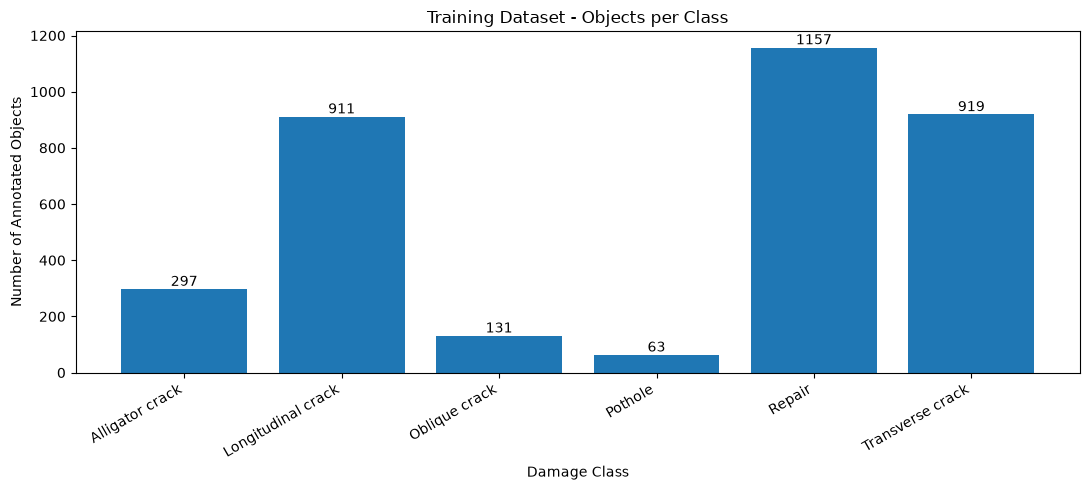

In [3]:
fig, ax = plt.subplots(figsize=(11, 5))

train_counts = [
    class_counts["train"][i]
    for i in range(len(class_names))
]

bars = ax.bar(class_names, train_counts)

ax.set_title("Training Dataset - Objects per Class")
ax.set_xlabel("Damage Class")
ax.set_ylabel("Number of Annotated Objects")

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        str(int(height)),
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Number of boxes: 3478
Average relative box area: 0.0783
Median relative box area: 0.0395
Smallest relative box area: 0.000839
Largest relative box area: 0.714


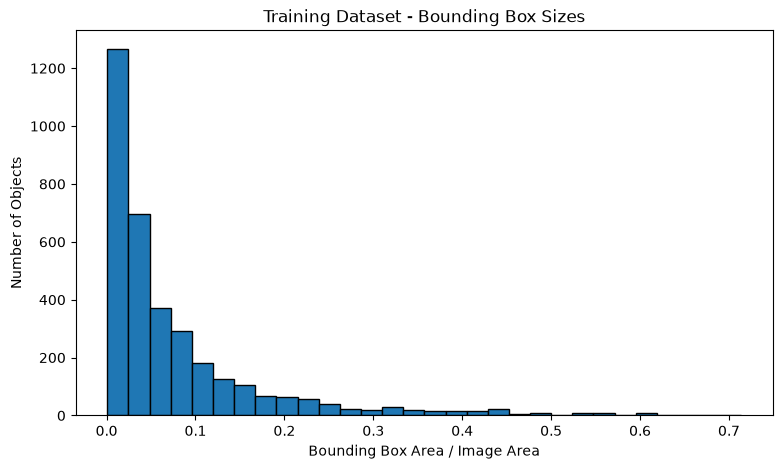

In [4]:
import numpy as np

train_areas = np.array(box_areas["train"])

print("Number of boxes:", len(train_areas))
print("Average relative box area:", round(train_areas.mean(), 4))
print("Median relative box area:", round(np.median(train_areas), 4))
print("Smallest relative box area:", round(train_areas.min(), 6))
print("Largest relative box area:", round(train_areas.max(), 4))

plt.figure(figsize=(9, 5))
plt.hist(train_areas, bins=30, edgecolor="black")

plt.title("Training Dataset - Bounding Box Sizes")
plt.xlabel("Bounding Box Area / Image Area")
plt.ylabel("Number of Objects")
plt.show()

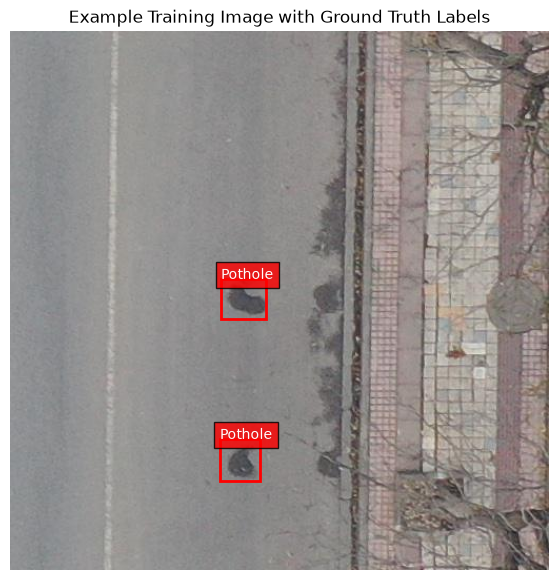

In [6]:
from PIL import Image
from matplotlib.patches import Rectangle

labels_folder = DATA / "train" / "labels"
images_folder = DATA / "train" / "images"

# Find an image containing a pothole (class 3)
for file in sorted(labels_folder.glob("*.txt")):
    lines = file.read_text().splitlines()

    if any(line.split()[0] == "3" for line in lines if line.strip()):
        label_file = file
        break

# Find the matching image
image_path = images_folder / (label_file.stem + ".jpg")

image = Image.open(image_path)
img_width, img_height = image.size

fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(image)

# Draw the bounding boxes
for line in label_file.read_text().splitlines():
    if not line.strip():
        continue

    class_id, x, y, w, h = map(float, line.split())

    x1 = (x - w / 2) * img_width
    y1 = (y - h / 2) * img_height

    rectangle = Rectangle(
        (x1, y1),
        w * img_width,
        h * img_height,
        fill=False,
        edgecolor="red",
        linewidth=2
    )

    ax.add_patch(rectangle)

    ax.text(
        x1,
        y1,
        class_names[int(class_id)],
        color="white",
        bbox={"facecolor": "red", "alpha": 0.8}
    )

ax.axis("off")
ax.set_title("Example Training Image with Ground Truth Labels")
plt.show()

## 2. YOLO11 Training Results

I fine-tuned a pretrained YOLO11n model for 30 epochs using a Tesla T4 GPU in Google Colab. The following graphs show how the model's performance changed during training.

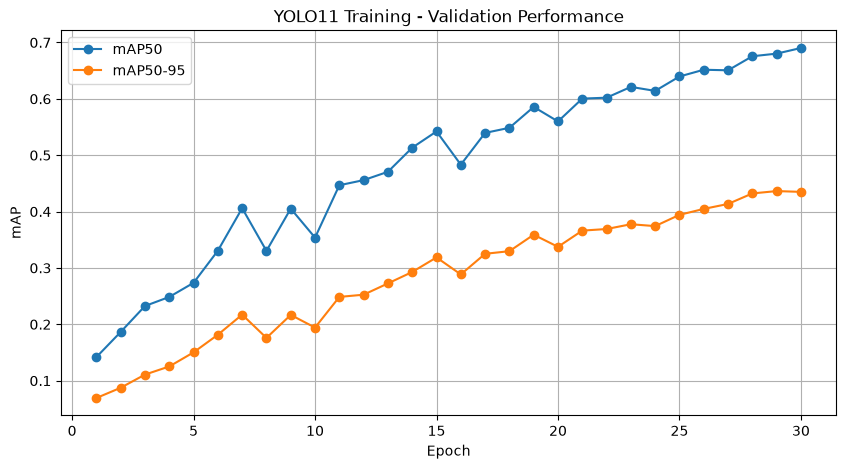

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.read_csv(
    "artifacts/asphalt_yolo11n_results.csv"
)

plt.figure(figsize=(10, 5))

plt.plot(
    results["epoch"],
    results["metrics/mAP50(B)"],
    label="mAP50",
    marker="o"
)

plt.plot(
    results["epoch"],
    results["metrics/mAP50-95(B)"],
    label="mAP50-95",
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("mAP")
plt.title("YOLO11 Training - Validation Performance")
plt.legend()
plt.grid(True)
plt.show()

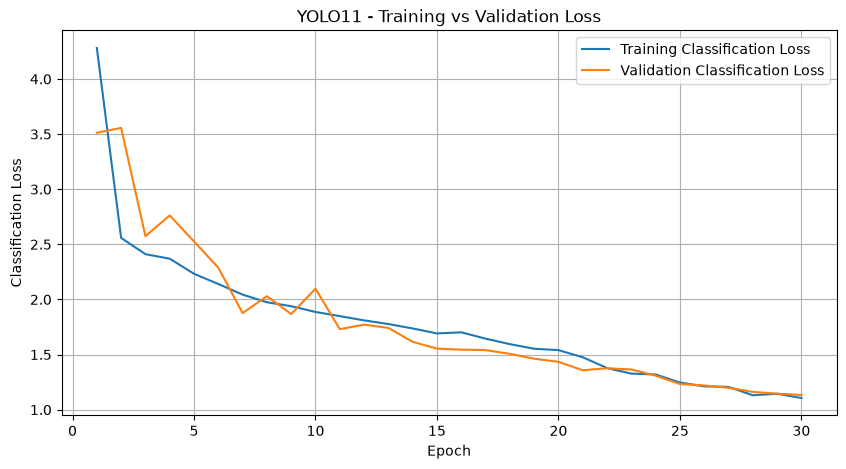

In [9]:
plt.figure(figsize=(10, 5))

plt.plot(
    results["epoch"],
    results["train/cls_loss"],
    label="Training Classification Loss"
)

plt.plot(
    results["epoch"],
    results["val/cls_loss"],
    label="Validation Classification Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Classification Loss")
plt.title("YOLO11 - Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

## 3. Fine-Tuned vs Scratch Model Comparison

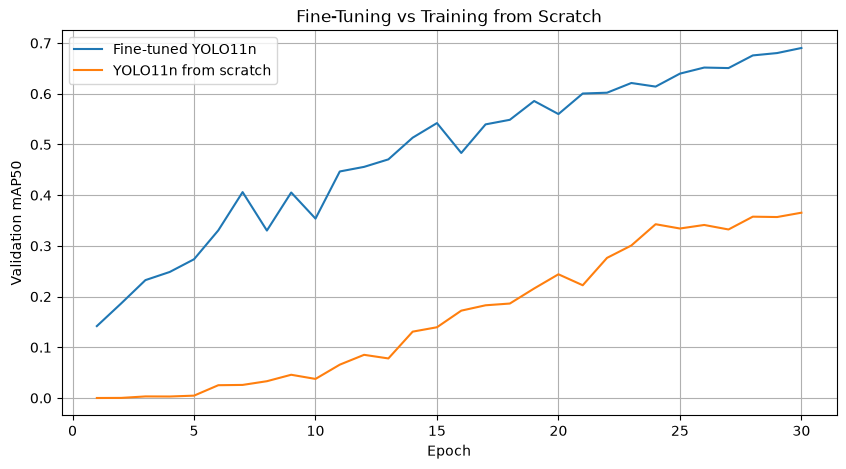

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

fine = pd.read_csv("artifacts/asphalt_yolo11n_results.csv")
scratch = pd.read_csv("artifacts/scratch_results.csv")

plt.figure(figsize=(10, 5))

plt.plot(
    fine["epoch"],
    fine["metrics/mAP50(B)"],
    label="Fine-tuned YOLO11n"
)

plt.plot(
    scratch["epoch"],
    scratch["metrics/mAP50(B)"],
    label="YOLO11n from scratch"
)

plt.xlabel("Epoch")
plt.ylabel("Validation mAP50")
plt.title("Fine-Tuning vs Training from Scratch")
plt.legend()
plt.grid(True)

plt.show()